# Explainable Credit Risk Assessment

## 1. Load the Data
- we will bring in the loan applicant data.
- this data has details like income, age, and loan amount.
- it also tells us who repaid and who defaulted.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('data/credit_risk_dataset.csv')
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


## 2. Exploratory Data Analysis (EDA)
- here we simply look at the data before touching it.
- we want to understand it first, then work on it.

# Basic information about the data
- check how many rows and columns we have.
- check the data type of each column.

In [3]:
df.shape
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.5 MB
None


# Missing values
- Find out which columns have empty or missing values.
- This tells is where we may need to fix things later.

In [4]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

# Target balance
- Check how many peoples defaulted vs how many repaid.
- This tells us if our data is balanaved or imbalanced.

In [5]:
df['loan_status'].value_counts()

loan_status
0    25473
1     7108
Name: count, dtype: int64

<Axes: xlabel='loan_status', ylabel='count'>

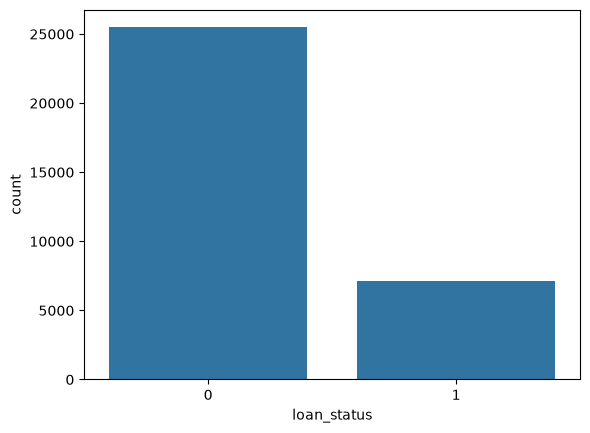

In [6]:
sns.countplot(x='loan_status', data=df)

# Outlier check
- Look for values that seem impossible, like age 144.
- these are signs of bad data entries.

In [7]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


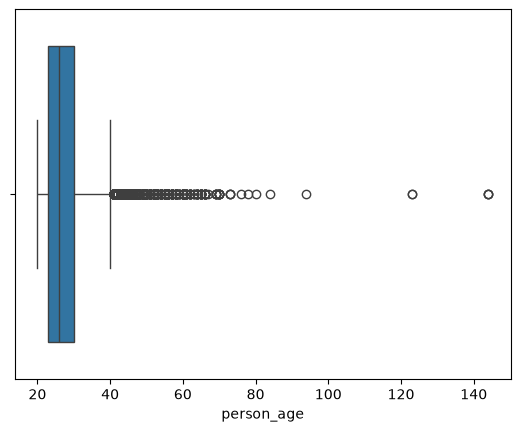

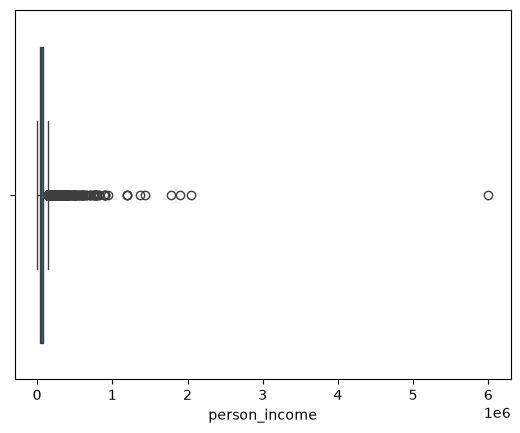

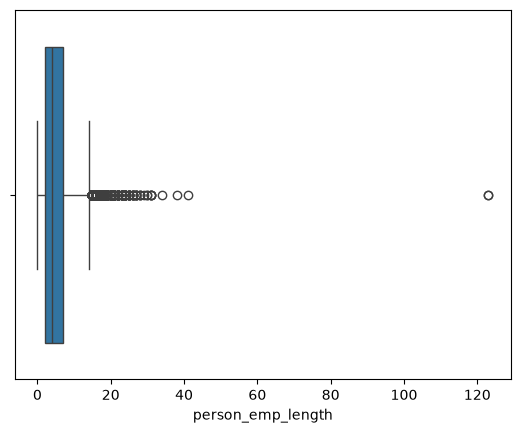

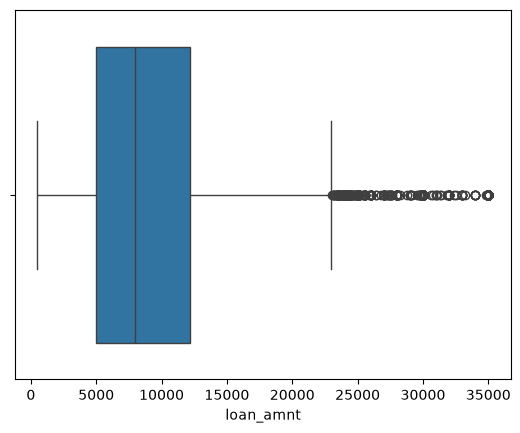

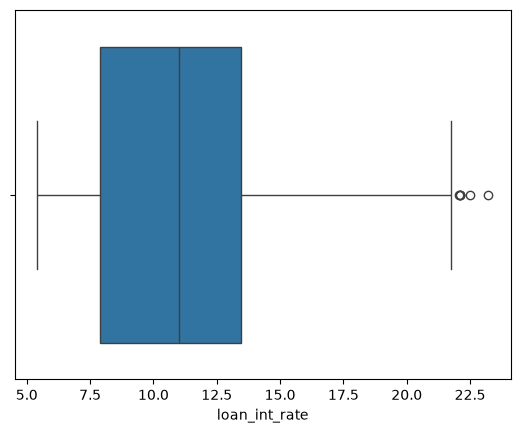

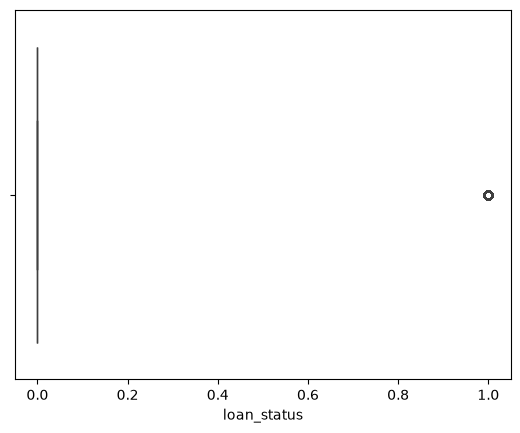

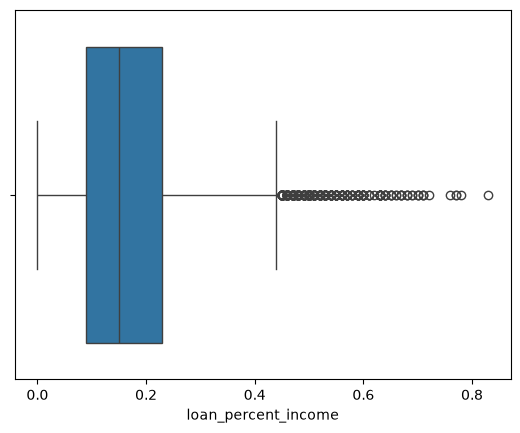

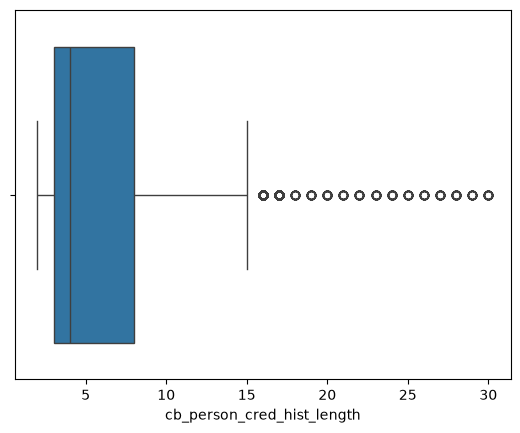

In [8]:
numerical_cols = df.select_dtypes(include=np.number).columns

for i in numerical_cols:
    sns.boxplot(x=df[i])
    plt.show()

In [9]:
(df["person_age"] > 100).sum()

np.int64(5)

In [10]:
(df["person_emp_length"] > 60).sum()

np.int64(2)

# Correlation check
- See how strong features are related to each other.
- this helps us spot repeated or linked information.

<Axes: >

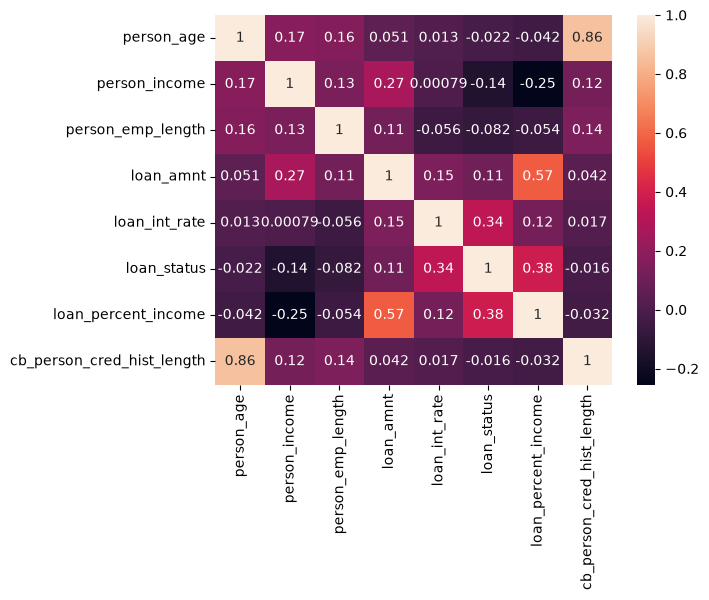

In [11]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

## 3. Data Validation & Outlier Handling
- Here we clean the data properly.
- we remove duplicate rows.
- we remove rows with an impossible age or work experience.
- we remove rows with zero or negative income and loan amount.
- we check if the interest rate looks realistic.
- we also flag rows where numbers don't add up correctly.

In [12]:
df_copy = df.copy()

print(f"Original shape: {df_copy.shape[0]}")

# Remove Duplicate rows
df_copy.drop_duplicates(inplace=True)
print(f"Rows after removing duplicates: {df_copy.shape[0]}")

# Remove ages below 18 and above 100
df_copy = df_copy[(df_copy["person_age"] >= 18)]
df_copy = df_copy[(df_copy["person_age"] <= 100)]

# Remove Employment length greater than age or extreme outliers (>60)
df_copy = df_copy[(df_copy["person_emp_length"] <= df_copy["person_age"])]
df_copy = df_copy[(df_copy["person_emp_length"] <= 60)]

# Remove the rows with zero or negative income and loan amount
df_copy = df_copy[(df_copy["loan_amnt"] > 0)]

# check if the interest rate looks realistic
print("Loan interest rate range from (min: 5.42 and max:23.22)")


Original shape: 32581
Rows after removing duplicates: 32416
Loan interest rate range from (min: 5.42 and max:23.22)


## 4. Features, Target & Train-Test Split
- we separate the data into input features and the target.
- the target is wheather the applicant defaulted or not.
- we split the data into a training part and a testing part.
- the model learns from the training part only.

In [13]:
x = df_copy.drop('loan_status', axis=1)
y = df_copy['loan_status']

In [14]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
# stratify = y mtlb 0 or 1 ko equal numbers me test or train me bhejenga

In [15]:
numerical_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file']

## 5. Handle Class Inbalance

- Very few people actually default in this data.
- if we ignore thism the model may just favor the majority class.
- we give more importance to the minority class during trainging.
- This helps the model actaully learn to spot degaulters.


In [16]:
# class - weights
# class weights technique ka kaam hai minority data side ko weightage dena jisse model minority data pr bhi dhyan de
# claculate krne ke liye jis targeted feeature ki majority jyda hai uska minority se divide krdo 
y_train.value_counts()

neg, pos = np.bincount(y_train)
scale_weights = neg/pos

In [17]:
scale_weights

np.float64(3.6312213039485766)

# 6. Data Preprocessing - Pipelines & column transformer
- Raw data is not ready for a model directly.
- we need to prepare numeric and text columns differently.
- we will build a pipeline for each model.
- we will use Columntransformer to apply different steps to different columns.

## Preprocessing for Logistic Regression
- Fill missing numeric values.
- Scale numeric values, since this midel is sensitive to scale.
- Convert category columns into numbers using one-hot encoding.

In [18]:
# Logistic Regression : impute + SCALE Numeric (numerical column pipeline), impute + One-Hot Encoding (categorical column pipeline)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor_lr = ColumnTransformer(
    transformers=[
        #Pipeline - for numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numerical_cols),

        #Pipeline - for categorical cols.
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols) 
    ]
)

## Preprocessing for XGBoost
- Fill missing numeric values.
- No scaling  needed here, since tree models don't need it.
- Convert category columns into numbers using one-hot encoding.

In [19]:
# XGBoost : impute numeric only (No Scaling),impute + One - Hot Encoding
preprocessor_xg = ColumnTransformer(
    transformers=[
        #Pipeline - for numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median'))
        ]), numerical_cols),

        #Pipeline - for categorical cols.
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols) 
    ]
)

## 7. Evaluation Helper Function
- We build one common function to check any model's performance.
- it will show accuracy, precision, recall, F1 score, and more.
- it will show a confusion matrix and a presision-recall curve.

In [20]:
# we have to evaluate logistic model and XGBoost modelon the basis of their metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, precision_recall_curve
def evaluate_model(model_name, model, x_test, y_test, threshold=None):
    
    y_pred_prob = model.predict_proba(x_test)[:,1]

    if threshold:
        y_pred = (y_pred_prob >= threshold).astype(int)
    else:
        y_pred = model.predict(x_test)

    #Metrics
    accuracy = accuracy_score(y_test,y_pred)  #overall mode's performance
    precision_s = precision_score(y_test,y_pred) # of the ones i picked, how many were actually right?
    recall_s = recall_score(y_test,y_pred) # out of wverything that was really there, how much did you manage to find?
    f1 = f1_score(y_test,y_pred) # harmonic mean of presision and recall

    
    # Confusion matrix
    cm = confusion_matrix(y_test,y_pred)
    class_report = classification_report(y_test, y_pred)

    print(f'Accuracy: {accuracy:.2f}')
    print(f'Presision: {precision_s:.2f}')
    print(f'Recall: {recall_s:.2f}')
    print(f'F1: {f1:.2f}')
    print()
    print(f'{model_name} Classification Report:')
    print(class_report)

    # Plotting confusion matrix
    sns.heatmap(cm, annot=True, fmt='d')
    plt.title(f'{model_name} Confusion Matrix')
    plt.ylabel('Actual Values')
    plt.xlabel('Predicted Values')
    plt.show()

    # Plotting ROC-AUC curve
    precisions, recalls, threshold = precision_recall_curve(y_test, y_pred_prob)
    plt.plot(recalls, precisions)
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(f'{model_name} Presision-Recall Curve')
    plt.show()

## 8. Stratified Cross-Validation
- One single train-test split may not be reliable.
- we split the training data into five folds instead.
- Each fold keeps the same defaultt vs repaid ratio.
- we check the model's score across all folds.

In [21]:
from sklearn.model_selection import StratifiedKFold, cross_validate 

cv = StratifiedKFold(n_splits=5, shuffle=True , random_state=42)

scoring = {'roc_auc':'roc_auc','accuracy':'accuracy','precision':'precision','recall':'recall','f1':'f1'}

In [22]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline= Pipeline([
    ('preprocessor', preprocessor_lr),
    ("classifier", LogisticRegression(max_iter=1000,class_weight="balanced", random_state=42))
])
lr_cv_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3I

In [23]:
# XGBoost Model
from xgboost import XGBClassifier

xgb_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.1,
        scale_pos_weight=scale_weights, random_state=42
    ))
])

In [24]:
for cv_name, pipe in [("Logistic Regression",lr_cv_pipeline),
                      ("XGBoost", xgb_cv_pipeline)]:
                        #print(cv_name, pipe)
                        cv_results = cross_validate(pipe, x_train, y_train,cv=cv,scoring=scoring, n_jobs=-1)

                        print(cv_name)
                        print(f"ROC-AUC: {cv_results['test_roc_auc'].mean()}")
                        print(f"Accuracy: {cv_results['test_accuracy'].mean()}")
                        print(f"Precision: {cv_results['test_precision'].mean()}")
                        print(f"Recall: {cv_results['test_recall'].mean()}")
                        print(f"F1: {cv_results['test_f1'].mean()}")
                        print()

Logistic Regression
ROC-AUC: 0.8705112830525306
Accuracy: 0.8115949542892269
Precision: 0.5448226008889892
Recall: 0.7781450872359963
F1: 0.6408013995933108

XGBoost
ROC-AUC: 0.9470945968526715
Accuracy: 0.917952083139717
Precision: 0.8190795992296656
Recall: 0.7963269054178144
F1: 0.8073360762846882



# 9. Baseline Model- Logistic regression
- we start with a simple model first.
- this becomes our benchmark to beat.
- we train it and check its score on the test data.

In [25]:
baseline_model = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(class_weight="balanced"))
])
baseline_model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped

Accuracy: 0.82
Presision: 0.56
Recall: 0.79
F1: 0.65

baseline_Logistic_model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



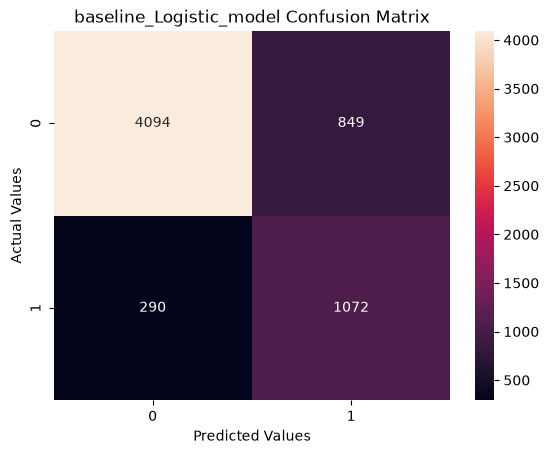

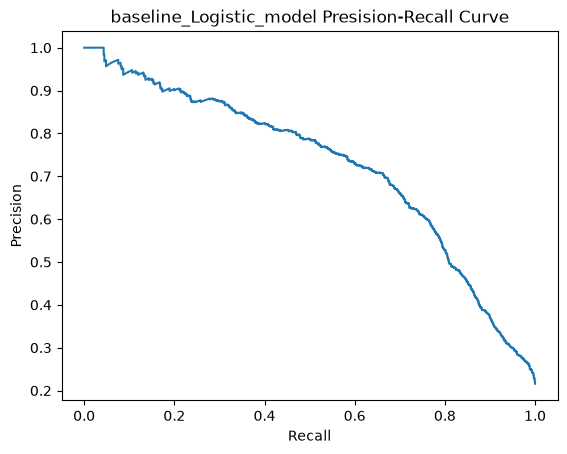

In [26]:
evaluate_model('baseline_Logistic_model',baseline_model,x_test,y_test)

## XGBoost Hyperparameter Tuning
- Now we move to a stronger model, XGboost.
- A model has many settings called hyperparameters.
- We search for the best combination of these settings.
- We use cross-validation while searching, sothe result is reliable.

In [27]:
xg_model = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(learning_rate = 0.1,
        scale_pos_weight=scale_weights, random_state = 42
    ))
])
xg_model.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped

Accuracy: 0.92
Presision: 0.82
Recall: 0.79
F1: 0.81

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      4943
           1       0.82      0.79      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.87      0.88      6305
weighted avg       0.92      0.92      0.92      6305



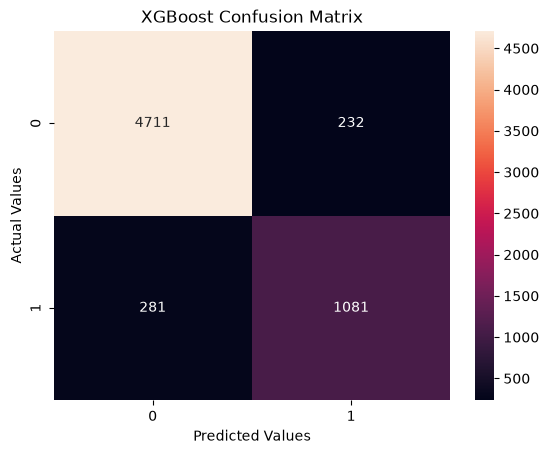

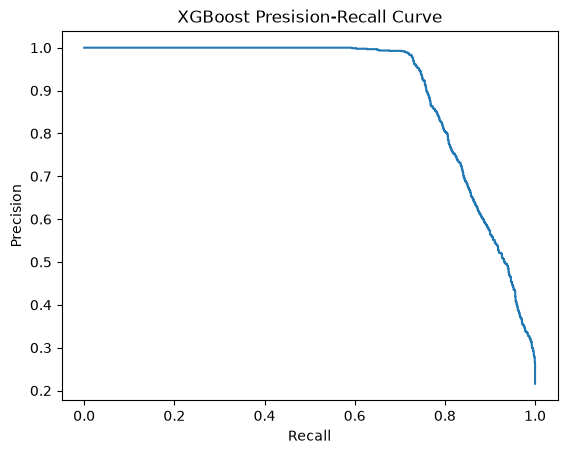

In [28]:
evaluate_model('XGBoost',xg_model,x_test,y_test) # this will be run after Hyperparameter tuning Xg boost model.

In [29]:
# lets perform hyperparameter tuning for XGBoost model using RandomizedSearchCV
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

param_grid = {
    'classifier__n_estimators': randint(150, 600),
    'classifier__max_depth': randint(3, 9),
    'classifier__learning_rate': uniform(0.01, 0.5),
    'classifier__subsample': uniform(0.6, 0.4),
    'classifier__colsample_bytree': uniform(0.6, 0.4),
    'classifier__min_child_weight': randint(1, 10),
    'classifier__gamma': uniform(0, 5)
}

# lower gamma -> more splits -> complex tree -> high overfitting risk
# higher gamma -> less splits -> simple tree -> low overfitting risk

In [30]:
random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring='average_precision',
    n_jobs=-1,
    verbose=1 
)

random_search.fit(x_train, y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__colsample_bytree': <scipy.stats....t 0x173b0d090>, 'classifier__gamma': <scipy.stats....t 0x355bee3f0>, 'classifier__learning_rate': <scipy.stats....t 0x173b1c440>, 'classifier__max_depth': <scipy.stats....t 0x173b0cb90>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",150
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index

In [31]:
print(f'best score: {random_search.best_score_}')
print(f'best params: {random_search.best_params_}')

best score: 0.9037243006693325
best params: {'classifier__colsample_bytree': np.float64(0.7687822878542048), 'classifier__gamma': np.float64(1.9818602585646454), 'classifier__learning_rate': np.float64(0.10975564880888293), 'classifier__max_depth': 7, 'classifier__min_child_weight': 2, 'classifier__n_estimators': 453, 'classifier__subsample': np.float64(0.8074852330604952)}


## 11. Compare Both Models side by side
- we now compare Logistic Regression and XGBoost.
- we look at their scores together in one table.
- This helps us pick the better performing model.

Accuracy: 0.82
Presision: 0.56
Recall: 0.79
F1: 0.65

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



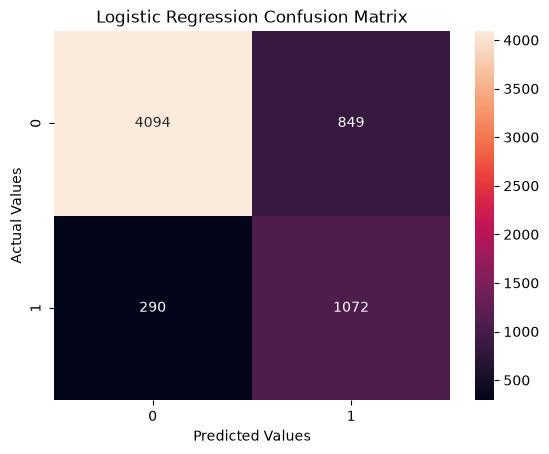

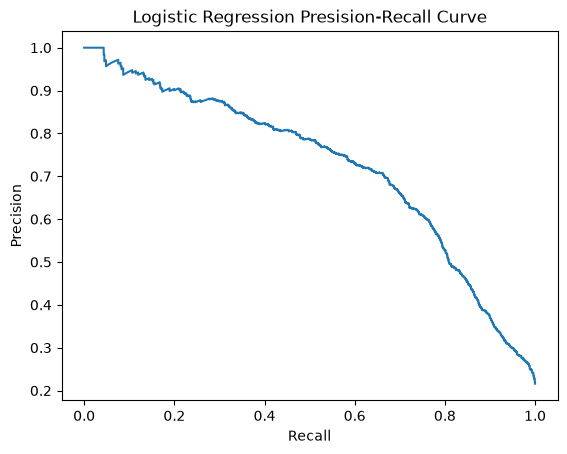

In [32]:
evaluate_model('Logistic Regression',baseline_model, x_test, y_test)

Accuracy: 0.93
Presision: 0.85
Recall: 0.80
F1: 0.83

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.96      0.95      4943
           1       0.85      0.80      0.83      1362

    accuracy                           0.93      6305
   macro avg       0.90      0.88      0.89      6305
weighted avg       0.93      0.93      0.93      6305



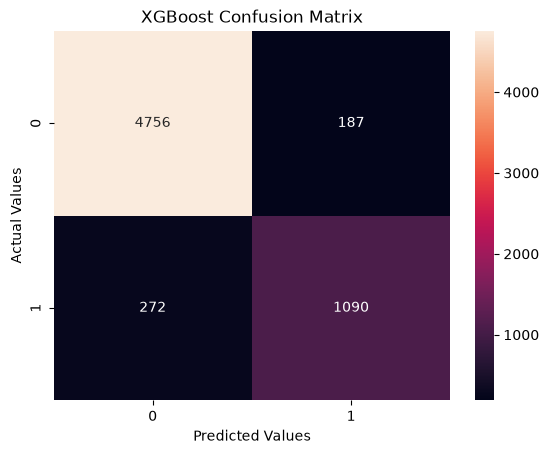

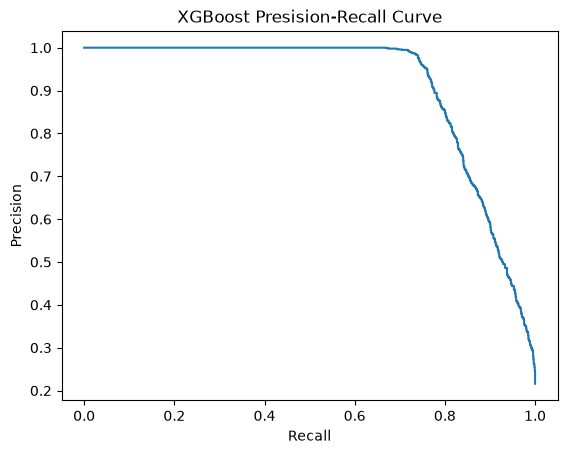

In [33]:
evaluate_model('XGBoost', random_search, x_test, y_test)

## 12. Optimizing the Classificaiton threshold
- The model gives a probability, not a direct yest or no.
- we decide a cut-off point to turn it into a decision.
- we check differenece cut-off points and pick the best one.

Accuracy: 0.78
Presision: 1.00
Recall: 0.00
F1: 0.00

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.78      1.00      0.88      4943
           1       1.00      0.00      0.00      1362

    accuracy                           0.78      6305
   macro avg       0.89      0.50      0.44      6305
weighted avg       0.83      0.78      0.69      6305



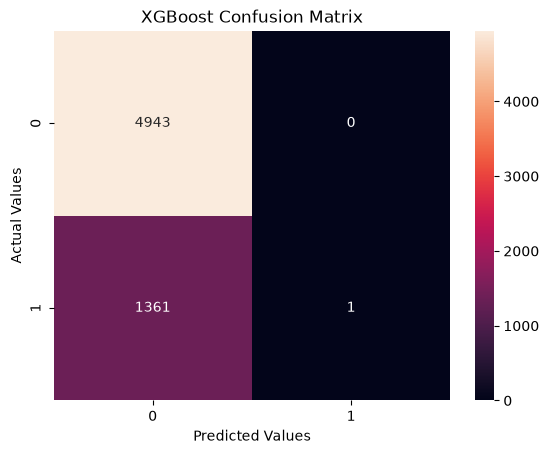

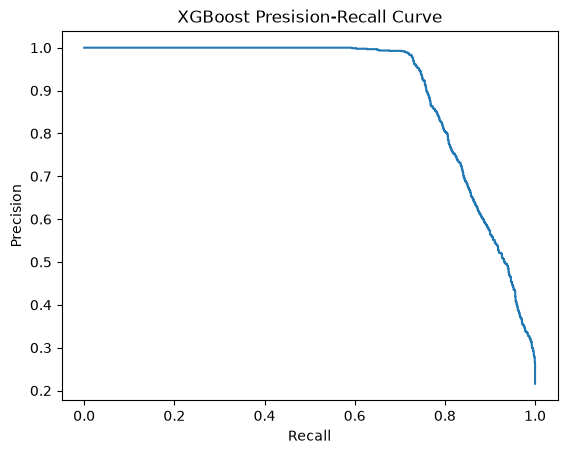

In [34]:
# Get the probabilities of the positive class (1) for XGBoost model
prob = xg_model.predict_proba(x_test)[:, 1]
# for each threshold,  claculate precision, recall, f1 score and plot the precision-recall curve
precisions, recalls, thresholds = precision_recall_curve(y_test, prob)
# calculate F1 score for each threshold
f1 = 2 * (precisions - recalls) / (precisions + recalls + 1e-9)  # Adding a small value to avoid division by zero
f1
# Get the thresholds that produces the hishest F1 score and use that threshold to evaluate the model
best = np.argmax(f1[:-1])  # Exclude the last value to avoid division by zero
best_threshold = thresholds[best]
# Evaluate the model using the best threshold
evaluate_model("XGBoost", xg_model, x_test, y_test,best_threshold)

## 13. Probability Calibration
- sometimes a model's probability doesn't mean what it says.
- for example, 30% risk should truly mean a 30% chance.
- we check this with a calibration plot.
- we fix it if the probabilities are off.